# SEM pore-size analysis

This notebook analyses the **maximum Feret diameter** measured with Fiji's **Analyze Particles** tool. The `Feret` column contains this measurement. Missing, non-numeric, non-finite, and non-positive entries are excluded; large pores are retained without outlier filtering.

Number- and area-weighted distributions use the same teal styling. Number-weighted distributions use fixed 10 micrometre bins, while area-weighted distributions use fixed 100 micrometre bins to show the contribution of large pores clearly. Sample size, bin width, and total projected pore area are methodological details and are therefore kept out of the plot area; the area-weighted distribution represents projected two-dimensional pore area rather than three-dimensional pore volume.

In [1]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / 'sem_pore_analysis.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not find sem_pore_analysis.py. Open the notebook from the '
        '3D_Printing_Project folder and restart the kernel.'
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import sem_pore_analysis
importlib.reload(sem_pore_analysis)

from sem_pore_analysis import (
    calculate_descriptive_statistics,
    calculate_pore_geometry_statistics,
    create_area_weighted_histogram,
    create_linear_histogram,
    create_logarithmic_histogram,
    load_feret_values,
    load_pore_measurements,
    save_figure,
)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 11,
})

# D1.25 specimen

## Configuration
Change `INPUT_CSV` to analyse another Fiji export.

In [2]:
INPUT_CSV = Path('SEM_analysis_outputs') / 'DF1.25' / 'Results.csv'
OUTPUT_DIR = Path('SEM_analysis_outputs') / 'DF1.25'
SAMPLE_NAME = 'DF1.25'
DISPLAY_MAX_UM = 250.0
LINEAR_BIN_WIDTH_UM = 10.0
AREA_WEIGHTED_BIN_WIDTH_UM = 100.0
LINEAR_NUMBER_OF_BINS = int(DISPLAY_MAX_UM / LINEAR_BIN_WIDTH_UM)
LOGARITHMIC_NUMBER_OF_BINS = 60
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Input: {INPUT_CSV.resolve()}')
print(f'Output: {OUTPUT_DIR.resolve()}')

Input: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\D1.25\Results.csv
Output: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\D1.25


## Data validation and descriptive statistics

In [3]:
feret_values, cleaning_summary = load_feret_values(INPUT_CSV)
statistics = calculate_descriptive_statistics(feret_values)

cleaning_table = pd.DataFrame({
    'Measure': ['Rows read', 'Valid Feret values', 'Invalid or missing values'],
    'Count': [
        cleaning_summary['rows_read'],
        cleaning_summary['valid_feret_values'],
        cleaning_summary['invalid_or_missing_values'],
    ],
})
display(cleaning_table)
display(statistics.style.format({'Value': '{:.3f}'}))

,Measure,Count
0,Rows read,483
1,Valid Feret values,483
2,Invalid or missing values,0


,Statistic,Value,Unit
0,Number of pores,483.000,count
1,Mean maximum Feret diameter,43.954,µm
2,Median maximum Feret diameter,20.307,µm
3,Standard deviation of maximum Feret diameter,77.938,µm
4,Smallest maximum Feret diameter,6.422,µm
5,Largest maximum Feret diameter,1167.056,µm
6,25th percentile of maximum Feret diameter,10.153,µm
7,75th percentile of maximum Feret diameter,47.407,µm


In [4]:
statistics_path = OUTPUT_DIR / 'pore_size_descriptive_statistics.csv'
statistics.to_csv(statistics_path, index=False)
print(f'Statistics exported to: {statistics_path.resolve()}')

Statistics exported to: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\D1.25\pore_size_descriptive_statistics.csv


## Count and area-weighted distributions with 5 micrometre-wide bins
The area-weighted plot sums the projected two-dimensional pore area in each maximum-Feret-diameter interval and divides it by the total measured pore area.

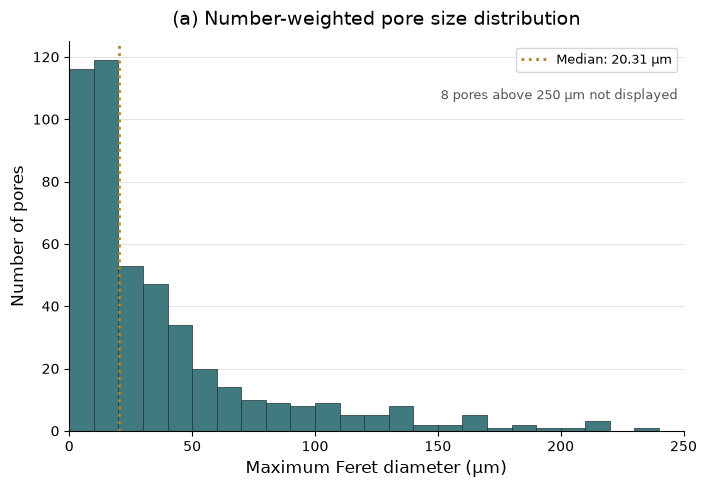

Area-weighted analysis: 483 valid pore measurements


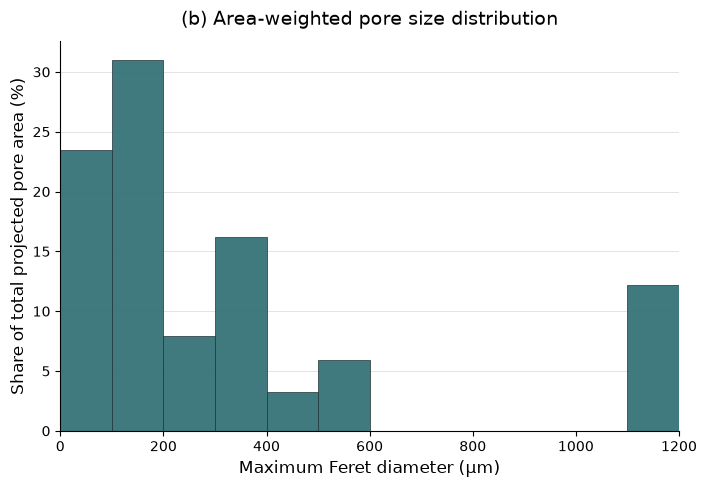

In [5]:
linear_figure = create_linear_histogram(
    feret_values, SAMPLE_NAME, DISPLAY_MAX_UM, LINEAR_NUMBER_OF_BINS
)
save_figure(linear_figure, OUTPUT_DIR / 'pore_size_distribution_linear_bins')
plt.show()

pore_measurements, area_cleaning_summary = load_pore_measurements(INPUT_CSV)
area_weighted_figure, area_weighted_distribution = create_area_weighted_histogram(
    pore_measurements, SAMPLE_NAME, DISPLAY_MAX_UM, AREA_WEIGHTED_BIN_WIDTH_UM
)
area_weighted_distribution.to_csv(
    OUTPUT_DIR / 'pore_area_weighted_distribution.csv', index=False
)
save_figure(
    area_weighted_figure, OUTPUT_DIR / 'pore_area_weighted_distribution'
)
print(f"Area-weighted analysis: {area_cleaning_summary['valid_pore_measurements']} valid pore measurements")
plt.show()

## Distribution with 60 logarithmically spaced bins
The logarithmic x-axis expands the small-pore region and shows the complete measured range. Only the linear plot is limited to 250 micrometres; larger measurements remain included in the statistics and are not removed as outliers.

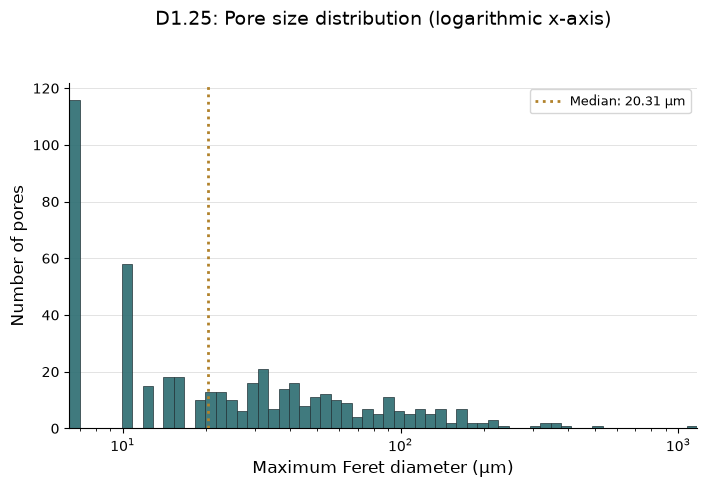

In [6]:
logarithmic_figure = create_logarithmic_histogram(
    feret_values, SAMPLE_NAME, DISPLAY_MAX_UM, LOGARITHMIC_NUMBER_OF_BINS
)
save_figure(
    logarithmic_figure,
    OUTPUT_DIR / 'pore_size_distribution_logarithmic_bins',
)
plt.show()

## Exported files
The output directory contains both histograms as 300 dpi PNG and vector PDF files, together with the descriptive-statistics CSV.

In [7]:
for output_path in sorted(OUTPUT_DIR.iterdir()):
    print(output_path.name)

pore_area_weighted_distribution.csv
pore_area_weighted_distribution.pdf
pore_area_weighted_distribution.png
pore_size_descriptive_statistics.csv
pore_size_distribution_linear_bins.pdf
pore_size_distribution_linear_bins.png
pore_size_distribution_logarithmic_bins.pdf
pore_size_distribution_logarithmic_bins.png
Results.csv


# SF1.25 specimen

The same maximum-Feret-diameter analysis is applied to the SF1.25 Fiji export. The 200 micrometre limit applies only to the linear plot; the logarithmic plot shows the complete measured range, and all valid measurements remain included in the statistics.

In [8]:
SF_INPUT_CSV = Path('SEM_analysis_outputs') / 'SF1.25' / 'Results.csv'
SF_OUTPUT_DIR = Path('SEM_analysis_outputs') / 'SF1.25'
SF_SAMPLE_NAME = 'SF1.25'
SF_DISPLAY_MAX_UM = 200.0
SF_LINEAR_NUMBER_OF_BINS = int(SF_DISPLAY_MAX_UM / LINEAR_BIN_WIDTH_UM)
SF_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Input: {SF_INPUT_CSV.resolve()}')
print(f'Output: {SF_OUTPUT_DIR.resolve()}')

Input: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\SF1.25\Results.csv
Output: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\SF1.25


## SF1.25 data validation and descriptive statistics

In [9]:
sf_feret_values, sf_cleaning_summary = load_feret_values(SF_INPUT_CSV)
sf_statistics = calculate_descriptive_statistics(sf_feret_values)

sf_cleaning_table = pd.DataFrame({
    'Measure': ['Rows read', 'Valid Feret values', 'Invalid or missing values'],
    'Count': [
        sf_cleaning_summary['rows_read'],
        sf_cleaning_summary['valid_feret_values'],
        sf_cleaning_summary['invalid_or_missing_values'],
    ],
})
display(sf_cleaning_table)
display(sf_statistics.style.format({'Value': '{:.3f}'}))

sf_statistics_path = SF_OUTPUT_DIR / 'pore_size_descriptive_statistics.csv'
sf_statistics.to_csv(sf_statistics_path, index=False)
print(f'Statistics exported to: {sf_statistics_path.resolve()}')

,Measure,Count
0,Rows read,695
1,Valid Feret values,695
2,Invalid or missing values,0


,Statistic,Value,Unit
0,Number of pores,695.000,count
1,Mean maximum Feret diameter,25.351,µm
2,Median maximum Feret diameter,13.173,µm
3,Standard deviation of maximum Feret diameter,42.378,µm
4,Smallest maximum Feret diameter,2.946,µm
5,Largest maximum Feret diameter,513.725,µm
6,25th percentile of maximum Feret diameter,4.657,µm
7,75th percentile of maximum Feret diameter,28.330,µm


Statistics exported to: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\SEM_analysis_outputs\SF1.25\pore_size_descriptive_statistics.csv


## SF1.25 count and area-weighted distributions with 5 micrometre-wide bins
The same projected-area weighting is applied using the complete SF1.25 measurement table.

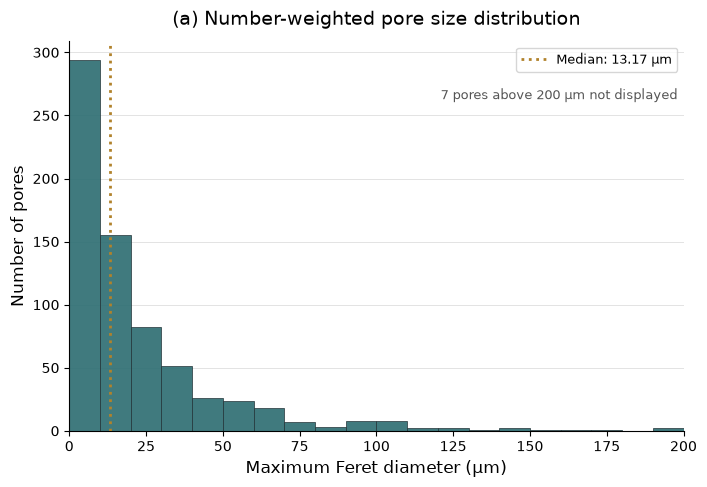

Area-weighted analysis: 695 valid pore measurements


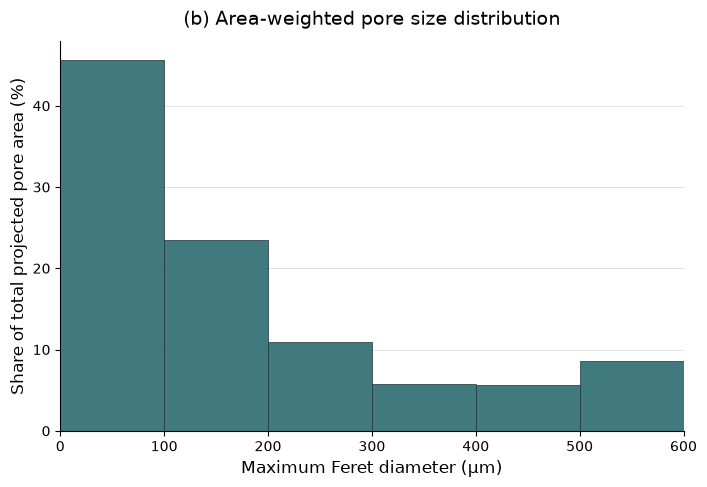

In [10]:
sf_linear_figure = create_linear_histogram(
    sf_feret_values, SF_SAMPLE_NAME, SF_DISPLAY_MAX_UM,
    SF_LINEAR_NUMBER_OF_BINS,
)
save_figure(
    sf_linear_figure,
    SF_OUTPUT_DIR / 'pore_size_distribution_linear_bins',
)
plt.show()

sf_pore_measurements, sf_area_cleaning_summary = load_pore_measurements(
    SF_INPUT_CSV
)
sf_area_weighted_figure, sf_area_weighted_distribution = (
    create_area_weighted_histogram(
        sf_pore_measurements, SF_SAMPLE_NAME, SF_DISPLAY_MAX_UM,
        AREA_WEIGHTED_BIN_WIDTH_UM,
    )
)
sf_area_weighted_distribution.to_csv(
    SF_OUTPUT_DIR / 'pore_area_weighted_distribution.csv', index=False
)
save_figure(
    sf_area_weighted_figure,
    SF_OUTPUT_DIR / 'pore_area_weighted_distribution',
)
print(f"Area-weighted analysis: {sf_area_cleaning_summary['valid_pore_measurements']} valid pore measurements")
plt.show()

## SF1.25 distribution with 60 logarithmically spaced bins
The logarithmic x-axis shows the complete measured range, including pores above 200 micrometres.

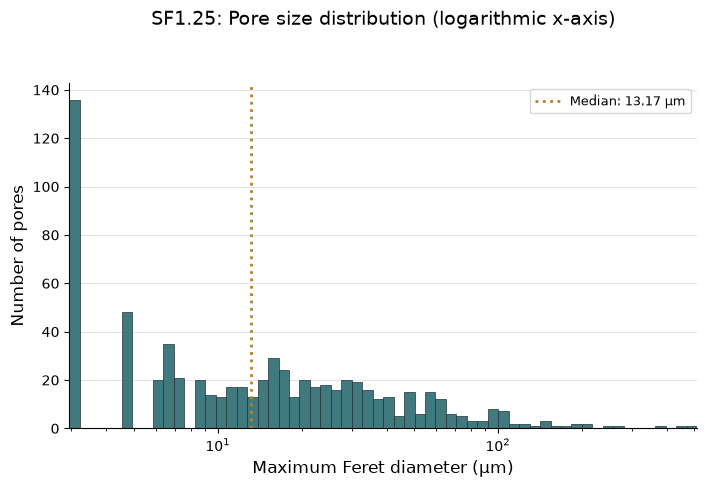

In [11]:
sf_logarithmic_figure = create_logarithmic_histogram(
    sf_feret_values, SF_SAMPLE_NAME, SF_DISPLAY_MAX_UM,
    LOGARITHMIC_NUMBER_OF_BINS,
)
save_figure(
    sf_logarithmic_figure,
    SF_OUTPUT_DIR / 'pore_size_distribution_logarithmic_bins',
)
plt.show()

In [12]:
for output_path in sorted(SF_OUTPUT_DIR.iterdir()):
    print(output_path.name)

pore_area_weighted_distribution.csv
pore_area_weighted_distribution.pdf
pore_area_weighted_distribution.png
pore_size_descriptive_statistics.csv
pore_size_distribution_linear_bins.pdf
pore_size_distribution_linear_bins.png
pore_size_distribution_logarithmic_bins.pdf
pore_size_distribution_logarithmic_bins.png
Results.csv


## Shared analysis helper for the remaining specimens

M04, M08, T3, and T4 use the same analysis steps. The helper keeps the calculations consistent while every specimen has its own titled section and output cell. Fiji measurements are converted from mm and mm² to µm and µm².

In [13]:
def analyse_specimen(
    sample_name, input_csv, *, input_unit='mm', display_max_um=250.0
):
    output_dir = input_csv.parent
    length_scale_to_um = 1000.0 if input_unit == 'mm' else 1.0
    number_of_bins = int(display_max_um / LINEAR_BIN_WIDTH_UM)

    feret, cleaning = load_feret_values(
        input_csv, length_scale_to_um=length_scale_to_um
    )
    pore_measurements, area_cleaning = load_pore_measurements(
        input_csv, length_scale_to_um=length_scale_to_um
    )
    statistics = calculate_descriptive_statistics(feret)
    geometry_statistics = calculate_pore_geometry_statistics(pore_measurements)
    statistics.to_csv(
        output_dir / 'pore_size_descriptive_statistics.csv', index=False
    )
    geometry_statistics.to_csv(
        output_dir / 'pore_geometry_descriptive_statistics.csv', index=False
    )
    pore_measurements.to_csv(
        output_dir / 'pore_geometry_measurements.csv', index=False
    )

    print(
        f'{sample_name}: {cleaning["valid_feret_values"]:,} valid pores; '
        f'{cleaning["invalid_or_missing_values"]:,} invalid/missing rows'
    )
    display(statistics.style.format({'Value': '{:.3f}'}))
    display(geometry_statistics.style.format({'Value': '{:.3f}'}))

    linear_figure = create_linear_histogram(
        feret, sample_name, display_max_um, number_of_bins
    )
    save_figure(
        linear_figure, output_dir / 'pore_size_distribution_linear_bins'
    )
    plt.show()

    area_figure, area_distribution = create_area_weighted_histogram(
        pore_measurements, sample_name, display_max_um, AREA_WEIGHTED_BIN_WIDTH_UM
    )
    area_distribution.to_csv(
        output_dir / 'pore_area_weighted_distribution.csv', index=False
    )
    save_figure(
        area_figure, output_dir / 'pore_area_weighted_distribution'
    )
    print(
        f'Area-weighted analysis: '
        f'{area_cleaning["valid_pore_measurements"]:,} valid measurements'
    )
    plt.show()

    logarithmic_figure = create_logarithmic_histogram(
        feret, sample_name, display_max_um, LOGARITHMIC_NUMBER_OF_BINS
    )
    save_figure(
        logarithmic_figure,
        output_dir / 'pore_size_distribution_logarithmic_bins',
    )
    plt.show()

    return statistics

# M04 specimen

Count-based, area-weighted, and logarithmic pore-size distributions for M04. Linear bars use a 250 µm display limit and 10 micrometre bins.

M04: 21,990 valid pores; 0 invalid/missing rows


,Statistic,Value,Unit
0,Number of pores,21990.000,count
1,Mean maximum Feret diameter,21.656,µm
2,Median maximum Feret diameter,7.000,µm
3,Standard deviation of maximum Feret diameter,44.614,µm
4,Smallest maximum Feret diameter,3.000,µm
5,Largest maximum Feret diameter,1544.000,µm
6,25th percentile of maximum Feret diameter,3.000,µm
7,75th percentile of maximum Feret diameter,23.000,µm


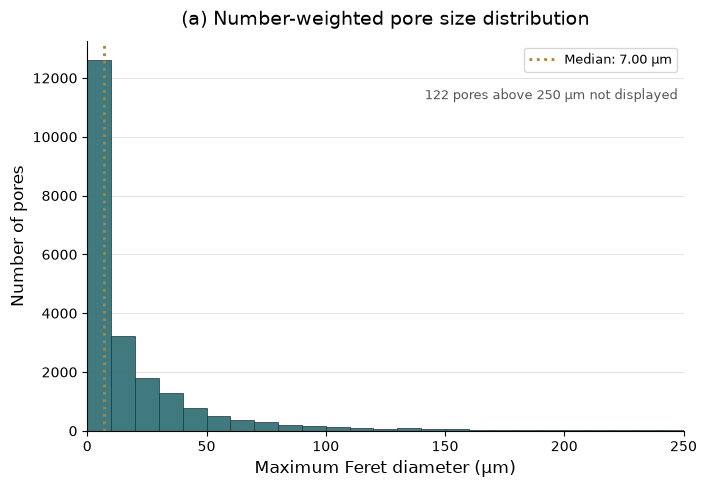

Area-weighted analysis: 21,990 valid measurements


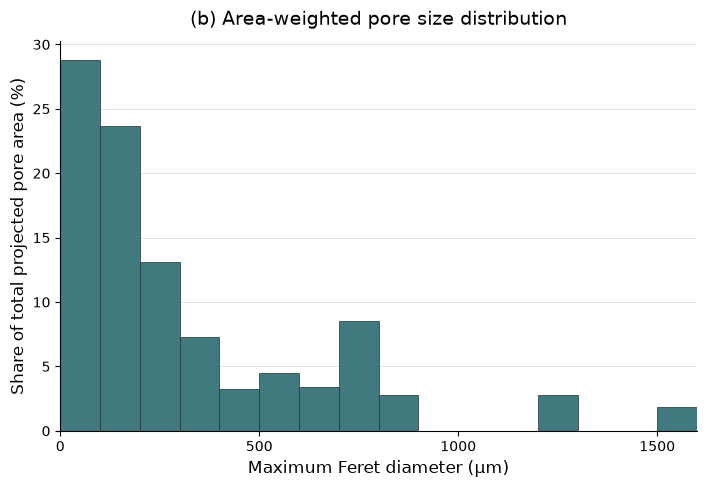

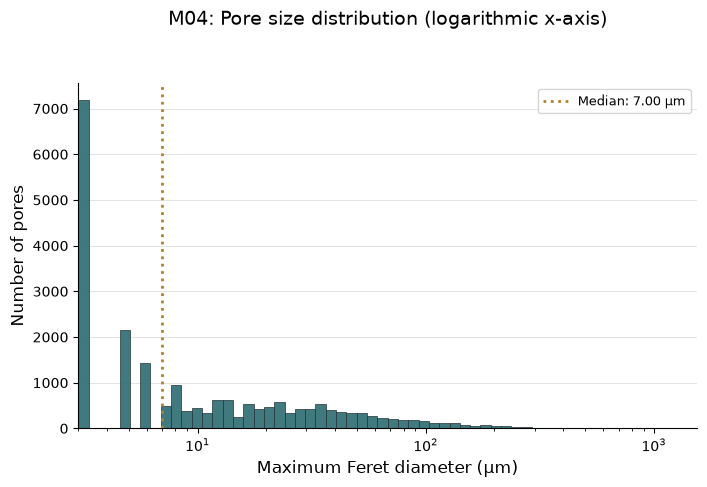

In [14]:
M04_INPUT_CSV = Path('SEM_analysis_outputs/M04/Results.csv')
m04_statistics = analyse_specimen('M04', M04_INPUT_CSV)

# M08 specimen

Count-based, area-weighted, and logarithmic pore-size distributions for the complete measured M08 area. `Results_all.csv` supplies all individual pores, while `Summary_all.csv` supplies Fiji's whole-image count, total pore area, and area fraction. Linear bars use a 250 µm display limit and 10 micrometre bins.

In [ ]:
M08_INPUT_CSV = Path('SEM_analysis_outputs/M08/Results_all.csv')
M08_SUMMARY_CSV = Path('SEM_analysis_outputs/M08/Summary_all.csv')
m08_statistics = analyse_specimen('M08', M08_INPUT_CSV)
m08_imagej_summary = pd.read_csv(M08_SUMMARY_CSV)
if int(m08_imagej_summary.loc[0, 'Count']) != int(m08_statistics.loc[0, 'Value']):
    raise ValueError('M08 Results_all and Summary_all pore counts do not match.')
display(m08_imagej_summary.style.format(precision=3).hide(axis='index'))

# T3 specimen

Count-based, area-weighted, and logarithmic pore-size distributions for T3. Linear bars use a 250 µm display limit and 10 micrometre bins.

T3: 16,827 valid pores; 0 invalid/missing rows


,Statistic,Value,Unit
0,Number of pores,16827.000,count
1,Mean maximum Feret diameter,28.086,µm
2,Median maximum Feret diameter,14.000,µm
3,Standard deviation of maximum Feret diameter,78.076,µm
4,Smallest maximum Feret diameter,3.000,µm
5,Largest maximum Feret diameter,3311.000,µm
6,25th percentile of maximum Feret diameter,7.000,µm
7,75th percentile of maximum Feret diameter,27.000,µm


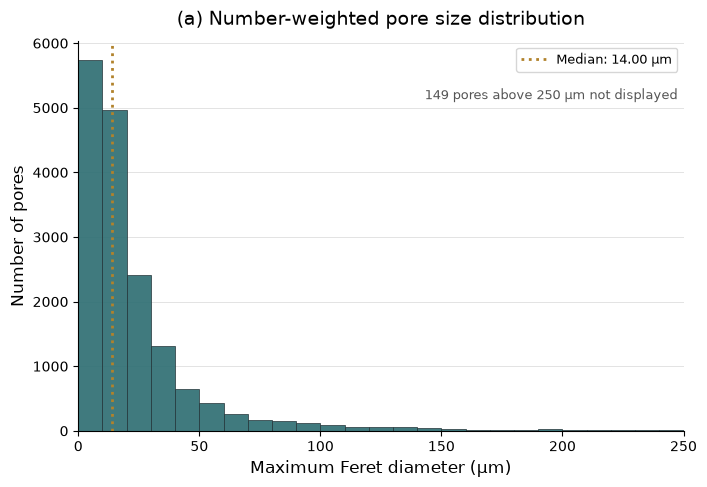

Area-weighted analysis: 16,827 valid measurements


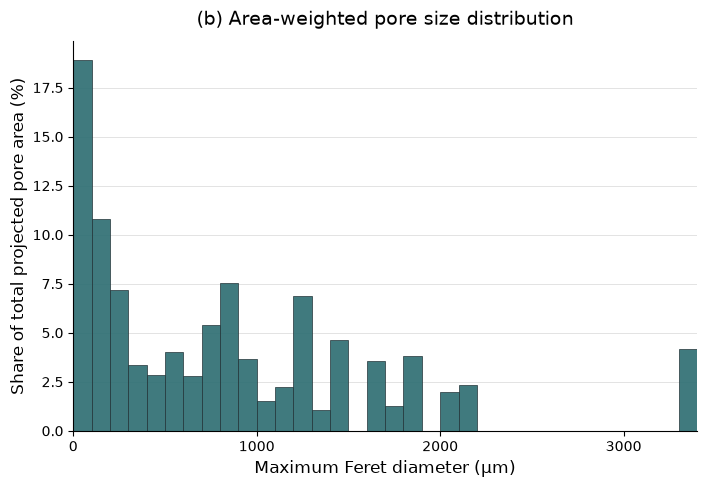

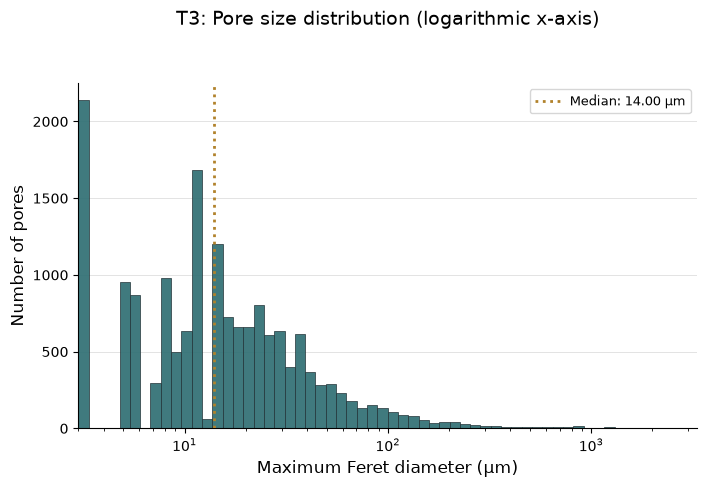

In [16]:
T3_INPUT_CSV = Path('SEM_analysis_outputs/T3/Results.csv')
t3_statistics = analyse_specimen('T3', T3_INPUT_CSV)

# T4 specimen

Count-based, area-weighted, and logarithmic pore-size distributions for T4. Linear bars use a 250 µm display limit and 10 micrometre bins.

T4: 41,917 valid pores; 0 invalid/missing rows


,Statistic,Value,Unit
0,Number of pores,41917.000,count
1,Mean maximum Feret diameter,28.239,µm
2,Median maximum Feret diameter,17.000,µm
3,Standard deviation of maximum Feret diameter,59.089,µm
4,Smallest maximum Feret diameter,3.000,µm
5,Largest maximum Feret diameter,2891.000,µm
6,25th percentile of maximum Feret diameter,5.000,µm
7,75th percentile of maximum Feret diameter,33.000,µm


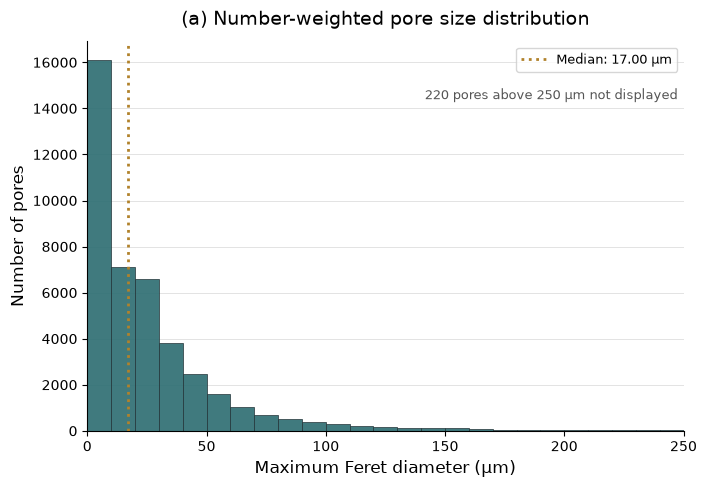

Area-weighted analysis: 41,917 valid measurements


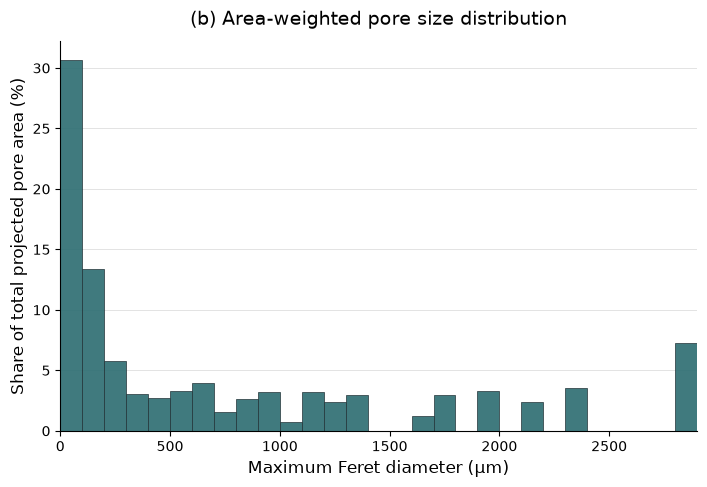

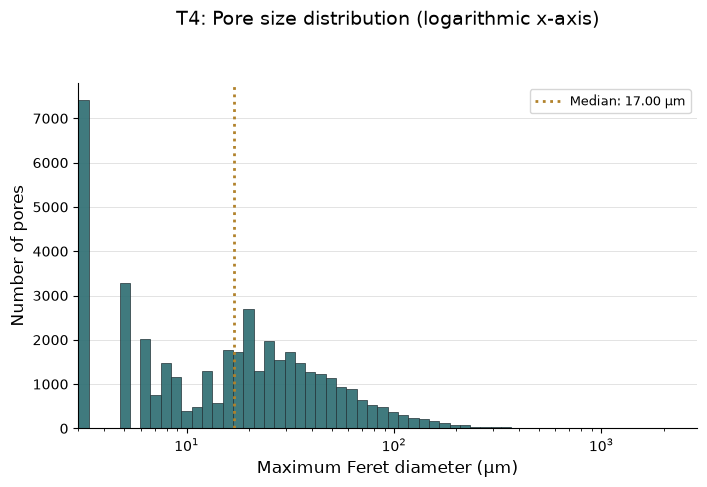

In [17]:
T4_INPUT_CSV = Path('SEM_analysis_outputs/T4/Results.csv')
t4_statistics = analyse_specimen('T4', T4_INPUT_CSV)

# Summary across all specimens

One row per specimen combining number-weighted Feret statistics with projected-area metrics.

In [ ]:
summary_specimens = [
    ('DF1.25', Path('SEM_analysis_outputs/DF1.25/Results.csv'), 1.0, None),
    ('SF1.25', Path('SEM_analysis_outputs/SF1.25/Results.csv'), 1.0, None),
    ('M04', Path('SEM_analysis_outputs/M04/Results.csv'), 1000.0, None),
    ('M08', Path('SEM_analysis_outputs/M08/Results_all.csv'), 1000.0, Path('SEM_analysis_outputs/M08/Summary_all.csv')),
    ('T3', Path('SEM_analysis_outputs/T3/Results.csv'), 1000.0, None),
    ('T4', Path('SEM_analysis_outputs/T4/Results.csv'), 1000.0, None),
]

summary_rows = []
for sample_name, csv_path, length_scale_to_um, imagej_summary_path in summary_specimens:
    feret_values, feret_cleaning = load_feret_values(
        csv_path, length_scale_to_um=length_scale_to_um
    )
    pore_measurements, _ = load_pore_measurements(
        csv_path, length_scale_to_um=length_scale_to_um
    )
    pore_areas = pore_measurements['Area']
    imagej_total_area_um2 = pore_areas.sum()
    imagej_area_fraction_percent = float('nan')
    if imagej_summary_path is not None:
        imagej_summary = pd.read_csv(imagej_summary_path).iloc[0]
        if int(imagej_summary['Count']) != int(feret_values.size):
            raise ValueError(f'{sample_name}: Results and Summary counts differ.')
        imagej_total_area_um2 = float(imagej_summary['Total Area']) * length_scale_to_um**2
        imagej_area_fraction_percent = float(imagej_summary['%Area'])
    large_pore_mask = pore_measurements['Feret'] > 500.0
    summary_rows.append({
        'Sample': sample_name,
        'Pores (n)': int(feret_values.size),
        'Invalid/missing rows': feret_cleaning['invalid_or_missing_values'],
        'Mean Feret (um)': feret_values.mean(),
        'Median Feret (um)': feret_values.median(),
        'D10 Feret (um)': feret_values.quantile(0.10),
        'D50 Feret (um)': feret_values.quantile(0.50),
        'D90 Feret (um)': feret_values.quantile(0.90),
        'SD Feret (um)': feret_values.std(ddof=1),
        'Q1 Feret (um)': feret_values.quantile(0.25),
        'Q3 Feret (um)': feret_values.quantile(0.75),
        'Minimum Feret (um)': feret_values.min(),
        'Maximum Feret (um)': feret_values.max(),
        'Pores >500 um (n)': int((feret_values > 500.0).sum()),
        'Pores >500 um (%)': 100.0 * (feret_values > 500.0).mean(),
        'Total projected pore area (um2)': pore_areas.sum(),
        'Mean pore area (\u00b5m\u00b2)': pore_areas.mean(),
        'Median pore area (\u00b5m\u00b2)': pore_areas.median(),
        'Mean equivalent circular diameter (um)': pore_measurements['Equivalent circular diameter'].mean(),
        'Median equivalent circular diameter (um)': pore_measurements['Equivalent circular diameter'].median(),
        'Mean minimum Feret (um)': pore_measurements['MinFeret'].mean(),
        'Mean Feret X span (um)': pore_measurements['Feret X span'].mean(),
        'Mean Feret Y span (um)': pore_measurements['Feret Y span'].mean(),
        'Mean Feret X coordinate (px)': pore_measurements['FeretX'].mean(),
        'Mean Feret Y coordinate (px)': pore_measurements['FeretY'].mean(),
        'ImageJ total pore area (um2)': imagej_total_area_um2,
        'ImageJ pore area fraction (%)': imagej_area_fraction_percent,
        'Projected area >500 um (%)': (
            100.0 * pore_areas.loc[large_pore_mask].sum() / pore_areas.sum()
        ),
        'Number-weighted bin width (um)': LINEAR_BIN_WIDTH_UM,
        'Area-weighted bin width (um)': AREA_WEIGHTED_BIN_WIDTH_UM,
    })

sem_pore_summary = pd.DataFrame(summary_rows)
summary_path = Path('SEM_analysis_outputs/sem_pore_summary.csv')
sem_pore_summary.to_csv(summary_path, index=False)
display(sem_pore_summary.style.format({
    column: '{:,.2f}'
    for column in sem_pore_summary.columns
    if column not in {'Sample', 'Pores (n)', 'Invalid/missing rows', 'Pores >500 um (n)'}
}).hide(axis='index'))
print(f'Summary exported to: {summary_path.resolve()}')

## EDS analysis and estimated composition

The PAD file contains map acquisitions of the same field at 5 and 20 kV. The spectra and maps support a **Cu-rich matrix**. The 20 kV spectrum gives the strongest identification because the separated Cu K-alpha and K-beta peaks are visible near 8.05 and 8.90 keV.

In the estimated-composition tables, **n.d.** means *not reliably determined by the semi-quantitative non-negative peak fit*. It does not mean that the element is absent. In particular, the VF3_DF oxygen map contains localized signal even though the 20 kV bulk peak fit cannot assign a defensible positive O wt.% value.

Oxygen is concentrated around dark curved features and inclusions, while Cu is broadly distributed through the matrix. This is consistent with oxygen-rich non-matrix regions or surface oxidation, but the maps alone cannot distinguish those mechanisms. Carbon is widespread, although its origin is ambiguous because binder, mounting medium, coating, and chamber contamination can contribute.

Cr, Nd, and La were auto-selected only in the 5 kV acquisition. Their low-energy lines overlap strongly with O-K and Cu-L, so they are **not considered confirmed**. The 20 kV acquisition also has 44.4% detector dead time; it is useful for qualitative identification, but precise composition should come from vendor-corrected quantification at a lower count rate.

The composition tables below are explicitly **estimated wt.%** values. The supplied T3 table is retained as the reference, and the other 20 kV summed spectra are fitted and transferred to that response calibration. This keeps the specimen comparison internally consistent, but it is still semi-quantitative and should not be presented as a vendor ZAF/Phi-Rho-Z result.

In [ ]:
from IPython.display import Image, display
from sem_eds_analysis import analyze_pad
from sem_eds_wt_estimates import main as build_eds_wt_estimates

eds_pad = Path('SEM_analysis_outputs/T3/T3_2.pad')
eds_output = Path('SEM_analysis_outputs/T3/EDS_analysis')
if not (eds_output / 'acquisition_summary.csv').exists():
    analyze_pad(eds_pad, eds_output)

eds_acquisitions = pd.read_csv(eds_output / 'acquisition_summary.csv')
eds_map_channels = pd.read_csv(eds_output / 'quant_map_channels.csv')
display(eds_acquisitions.style.format(precision=2).hide(axis='index'))
display(eds_map_channels.style.format({'Preview intensity scale': '{:.3g}'}).hide(axis='index'))

for acquisition in ('T3-x1000-5kV', 'T3x1000-20kV'):
    display(Image(filename=str(eds_output / acquisition / 'summed_spectrum.png'), width=1050))
    display(Image(filename=str(eds_output / acquisition / 'elemental_map_montage.png'), width=1050))

eds_combined_path = Path('SEM_analysis_outputs/eds_estimated_wt_percent_all_specimens.csv')
eds_inventory_path = Path('SEM_analysis_outputs/eds_pad_inventory.csv')
build_eds_wt_estimates()  # Rescan specimen folders for newly added PAD files.

eds_inventory = pd.read_csv(eds_inventory_path)
eds_composition_long = pd.read_csv(eds_combined_path)
eds_composition_wide = (
    eds_composition_long
    .pivot(index='Specimen', columns='Element', values='Estimated wt%')
)
eds_composition_wide['Total'] = eds_composition_wide.sum(axis=1)
display(eds_inventory.style.hide(axis='index'))
display(eds_composition_wide.style.format('{:.2f}', na_rep='n.d.'))

eds_specimen_folders = {'VF3_DF': 'DF1.25', 'VF3_SF': 'SF1.25'}
for specimen in eds_composition_wide.index:
    specimen_folder = eds_specimen_folders.get(specimen, specimen)
    table_image = Path('SEM_analysis_outputs') / specimen_folder / 'EDS_analysis' / 'estimated_wt_percent.png'
    if table_image.exists():
        display(Image(filename=str(table_image), width=500))

# Copper-particle morphology in green VF1 and VF2 filaments

The table reports the recommended particle descriptors: detected-particle count, detected copper-particle area fraction, mean particle area, number-weighted D10/D50/D90 of the maximum Feret diameter, mean circularity, and mean solidity. Mean minimum particle diameter is omitted.

The ImageJ exports are not spatially calibrated: one-pixel objects have `Area = 1` and `Feret = 1.414`. Areas and diameters are therefore reported in px² and px rather than incorrectly labelling them as micrometres. The area fraction uses the complete 1024 × 768 px analyzed raster indicated by the exported particle coordinates. Replace this raster size if a cropped region was analyzed.

In [ ]:
from sem_particle_analysis import create_green_filament_particle_summary

green_filament_particle_csvs = {
    'VF1': Path('SEM_analysis_outputs/particle_size_VF1.csv'),
    'VF2': Path('SEM_analysis_outputs/particle_size_VF2.csv'),
}
green_filament_particle_summary = create_green_filament_particle_summary(
    green_filament_particle_csvs,
    image_width_px=1024,
    image_height_px=768,
)
particle_summary_path = Path(
    'SEM_analysis_outputs/green_filament_copper_particle_summary.csv'
)
green_filament_particle_summary.to_csv(particle_summary_path, index=False)
display(
    green_filament_particle_summary.style.format({
        'Copper particle area fraction (%)': '{:.2f}',
        'Mean particle area (px^2)': '{:.2f}',
        'D10 maximum Feret diameter (px)': '{:.3f}',
        'D50 maximum Feret diameter (px)': '{:.3f}',
        'D90 maximum Feret diameter (px)': '{:.3f}',
        'Mean circularity (-)': '{:.3f}',
        'Mean solidity (-)': '{:.3f}',
    }).hide(axis='index')
)
print(f'Summary exported to: {particle_summary_path.resolve()}')